# pHLemon-rev FRET visualization and video

This notebook generates a video showing donor and acceptor fluorescence, per-cell FRET pseudo-color images, and the corresponding mean FRET time course for the pHLemon-rev sensor. It uses the supplied cell masks and previously calculated FRET values to display the same cells across the available image frames.

The provided images are representative crops from a larger field of view. The neural-network segmentation was performed on the original full-size images, and the resulting cell masks and FRET measurements are included with this example. This notebook does not repeat neural-network segmentation or FRET calculation. The pretrained network should be applied to full-size images consistent with its training input, rather than these cropped images.

Image frames are not necessarily consecutive acquisition time points. Frames affected by the abrupt shift associated with the onset of breathing or by unstable movement were excluded before preparing this dataset. The remaining observations can be used for interpolation when displaying cell trajectories or a continuous time course; interpolated values should not be treated as additional experimental measurements. The notebook visualizes the prepared data rather than performing the original movement filtering.

The visualization functions and settings are defined in `functions.py`. The notebook adjusts panel placement and the displayed time-course plot size, keeping the FRET image size and numerical calculations unchanged.

## Installation

Required packages can be installed with:

```bash
pip install numpy pandas matplotlib scipy tifffile ipywidgets ipython imageio imageio-ffmpeg
```

Keep `functions.py` in the same directory as this notebook.

In [1]:
from pathlib import Path
import matplotlib.pyplot as plt
from IPython.display import Video, display
from functions import (
    FRETVisualization,
    VisualizationSettings,
    show_interactive,
    export_video,
)

## Load prepared images and FRET measurements

The `Input_analysis_results/` folder contains the cropped donor and acceptor TIFF images, their corresponding neural-network-derived cell masks, and `cell_FRET.csv` with the previously calculated FRET values. The matching files are read using the sample name `pHLr`.

The images are a representative subset of the original recording, not a complete consecutive image sequence, due to the deletion of the breathing events. The analysis object loads the available time points and their associated measurements. Display parameters, including image intensity ranges, FRET colors, and video settings, are defined in `functions.py`.

In [2]:
# -------- Input and output folders --------
DATA_DIR = Path("Input analysis results")
OUTPUT_DIR = Path("Output exported video")

# Load the provided masks and FRET values for the selected sample.
analysis = FRETVisualization(
    DATA_DIR, sample_name="pHLr", settings=VisualizationSettings()
)
print(f"Input frames: {len(analysis.available_T)}")
print(f"FRET baseline: {analysis.fret_baseline:.6f}")

Input frames: 429
FRET baseline: 0.678508


In [3]:
# -------- Image-panel layout --------
# Keep the FRET panel at its original size, with smaller donor and acceptor
# images stacked on the left. Place their names vertically beside them.

import types

_original_plot_combined_frame = analysis.plot_combined_frame

def _stacked_plot_combined_frame(self, *args, **kwargs):
    fig = _original_plot_combined_frame(*args, **kwargs)

    # Find the three image panels, ordered from left to right.
    image_axes = sorted((ax for ax in fig.axes if ax.images),
                        key=lambda ax: ax.get_position().x0)
    if len(image_axes) < 3:
        raise RuntimeError("Expected donor, acceptor, and FRET image axes.")
    donor_ax, acceptor_ax, fret_ax = image_axes[:3]
    old_fret = fret_ax.get_position().frozen()

    # Move the FRET panel without resizing it.
    fret_left = 0.46
    fret_ax.set_position([fret_left, old_fret.y0, old_fret.width, old_fret.height])

    # Fit both images beside FRET without changing their pixel aspect ratio.
    fig_w, fig_h = fig.get_size_inches()
    vertical_gap = 0.018
    horizontal_gap = 0.030
    label_gap = 0.018
    label_left_margin = 0.075

    # Read source image dimensions rather than assuming square images.
    donor_h, donor_w = donor_ax.images[0].get_array().shape[:2]
    acceptor_h, acceptor_w = acceptor_ax.images[0].get_array().shape[:2]
    image_ratios = (donor_w / donor_h, acceptor_w / acceptor_h)
    max_image_height = (old_fret.height - vertical_gap) / 2
    available_width = fret_left - horizontal_gap - label_left_margin - label_gap
    image_height = min(max_image_height,
                       *(available_width * fig_w / (ratio * fig_h)
                         for ratio in image_ratios))
    donor_width = image_height * image_ratios[0] * fig_h / fig_w
    acceptor_width = image_height * image_ratios[1] * fig_h / fig_w
    image_right = fret_left - horizontal_gap
    acceptor_y = old_fret.y0
    donor_y = acceptor_y + image_height + vertical_gap
    donor_left = image_right - donor_width
    acceptor_left = image_right - acceptor_width
    acceptor_ax.set_position([acceptor_left, acceptor_y, acceptor_width, image_height])
    donor_ax.set_position([donor_left, donor_y, donor_width, image_height])

    # Keep labels the same size as the other panel headings, close to the images.
    title_size = fret_ax.title.get_fontsize()
    for ax, name, center_y, left in (
        (donor_ax, "Donor", donor_y + image_height / 2, donor_left),
        (acceptor_ax, "Acceptor", acceptor_y + image_height / 2, acceptor_left),
    ):
        ax.set_title("")
        ax.set_ylabel("")
        fig.text(left - label_gap, center_y, name, rotation=90,
                 ha="center", va="center", color="white", fontsize=title_size)

    # Move the existing FRET colorbar beside the repositioned FRET panel.
    colorbar_axes = [ax for ax in fig.axes if ax not in image_axes
                     and ax.get_position().x0 >= old_fret.x1 - 0.005
                     and ax.get_position().height > old_fret.height * 0.5]
    colorbar_right = fret_left + old_fret.width
    for bar_ax in colorbar_axes:
        p = bar_ax.get_position().frozen()
        gap = p.x0 - old_fret.x1
        new_x = fret_left + old_fret.width + gap
        bar_ax.set_position([new_x, p.y0, p.width, p.height])
        colorbar_right = max(colorbar_right, new_x + p.width)

    # Extend the time course across the labels and FRET colorbar.
    # Resize its height proportionally so the plot itself is not stretched.
    lower_axes = [ax for ax in fig.axes if ax not in image_axes
                  and ax not in colorbar_axes and ax.has_data()
                  and len(ax.lines) > 0]
    if lower_axes:
        curve_ax = min(lower_axes, key=lambda ax: ax.get_position().y0)
        p = curve_ax.get_position().frozen()
        # Center the plot under the full upper group, from the vertical
        # Donor/Acceptor labels to the FRET colorbar label.
        group_left = min(donor_left, acceptor_left) - label_gap - 0.02
        group_right = min(0.97, colorbar_right + 0.055)
        # Align both plot edges with the outer limits of the upper panels.
        # Scale height with width to preserve the original plot proportions.
        # Shift the lower plot slightly right and reduce both dimensions equally.
        plot_scale = 0.97     # 3% smaller, keeping the original proportions
        plot_shift_x = 0.025 # positive values move the plot to the right
        curve_width = (group_right - group_left) * plot_scale
        curve_height = p.height * (curve_width / p.width)
        curve_left = group_left + plot_shift_x
        top_limit = old_fret.y0 - 0.045
        curve_bottom = top_limit - curve_height
        curve_ax.set_position([curve_left, curve_bottom, curve_width, curve_height])

    return fig

# Apply the same panel layout to notebook previews and video export.
analysis.plot_combined_frame = types.MethodType(_stacked_plot_combined_frame, analysis)


## Preview the FRET visualization

Donor and acceptor are stacked on the left, with vertical labels close to each image. Both fluorescence images retain their original aspect ratios. The FRET pseudocolor panel and colorbar remain unchanged on the right.

The lower time-course plot aligns with the outer edges of the donor/acceptor labels and FRET colorbar, while preserving its width-to-height proportions. The first frame is displayed to check the layout before video export.

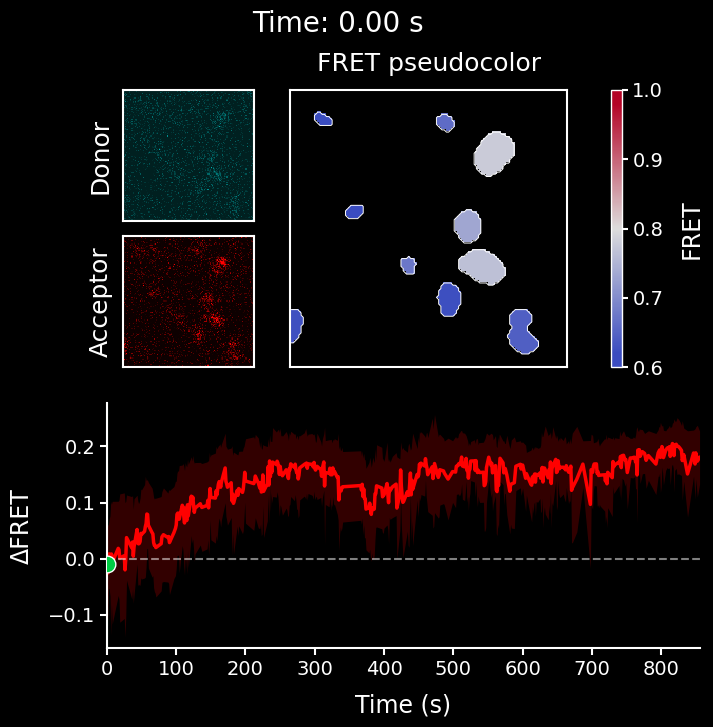

In [4]:
# Preview the first available frame.
fig = analysis.plot_combined_frame(0)
plt.show()

## Export the video and mean FRET time course

The video combines the available image frames with their FRET measurements. Because frames affected by breathing-related shifts and unstable movement were excluded during data preparation, the displayed sequence does not represent every acquired time point. Any interpolation used to display a continuous trajectory or time course is a visualization step and does not restore the excluded measurements.

The default exports all available visualization frames. `VIDEO_FRAME_INDICES` can be changed to export a subset. The generated MP4 and mean FRET table are saved in `output_exported_video/`.

The `mean_FRET.csv` file contains the time, mean FRET value, and cell-level variability for this sample; its error values do not represent variability across animals.

In [5]:
# -------- Video export --------
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

# None uses all available frames; provide frame indices to select a subset.
VIDEO_FRAME_INDICES = None

# Save the video and the corresponding mean FRET curve.
video_path = export_video(
    analysis, OUTPUT_DIR / "pHLr_analysis_video_results.mp4",
    indices=VIDEO_FRAME_INDICES,
)
csv_path = analysis.save_curve_csv(OUTPUT_DIR / "mean_FRET_per_view.csv")

print("Saved:", video_path)
print("Saved:", csv_path)

Saved: Output exported video/pHLr_analysis_video_results.mp4
Saved: Output exported video/mean_FRET_per_view.csv


## Preview the exported video

The saved MP4 is displayed below to check the final video. Playback follows the available visualization frames rather than the complete original acquisition.

In [6]:
# Play the saved video in the notebook.
display(Video(filename=str(video_path), embed=True, html_attributes="controls"))